In [75]:
import os
import sys
sys.path.insert(0, "./../../Python/cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
import glob
import joblib
import umap
from statistics import mean

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
#DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/dist_runs/')
#SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'stoch_sim*orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
# filenames_sp = [filenames[5], filenames[6], filenames[3], filenames[4], filenames[7], filenames[8], 
#                filenames[0], filenames[1], filenames[2]]

filenames_sp = [filenames[0], filenames[3], filenames[5], filenames[8],
                filenames[11], filenames[12], filenames[18], filenames[24]]

filenames_conds = [filenames[0], filenames[12], filenames[5],
                filenames[18], filenames[11], filenames[24]]

# filenames_sp = [filenames[3], filenames[0], filenames[1], filenames[2],
#                 filenames[4], filenames[5], filenames[6], filenames[7]]
# filenames_sp=filenames

filenames_sp


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff099_orig.csv']

In [4]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'ODE_sim*orig.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[0], filenames_ode[3], filenames_ode[5], filenames_ode[8],
                    filenames_ode[11], filenames_ode[12], filenames_ode[18], filenames_ode[25]]

filenames_conds_ode = [filenames_ode[0], filenames_ode[12], filenames_ode[5],
                    filenames_ode[18], filenames_ode[11], filenames_ode[25]]

# filenames_sp_ode = [filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[2],
#                     filenames_ode[4], filenames_ode[5], filenames_ode[6], filenames_ode[7]]
#filenames_sp_ode = filenames_ode

filenames_sp_ode


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff099_orig.csv']

In [5]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

#reducer save name
r_name = f'reducer_03_20_{init_dt}_{dt}_{window}_{time_step}.sav'
# r_name = f'reducer_pso0_{init_dt}_{dt}_{window}_{time_step}.sav'

In [6]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [7]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [9]:
def calc_minmax(filenames, filenames_ode):
    # values to be replaced
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this now
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [10]:
max_prots, min_prots = calc_minmax(filenames_sp, filenames_sp_ode)

In [11]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [12]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [13]:
np.amax(all_prot_tmp)

1.0

In [14]:
# reducer = joblib.load('C:\\Users\\olesk\\data\\reducer_07_25_0.1_0.1_4_0.5.sav')
reducer = joblib.load('C:\\Users\\olesk\\ECM_mod_output\\reducer_03_20_0.1_0.1_4_0.5.sav')

# reducer = joblib.load('C:\\Users\\olesk\\reducer_20240502_0.1_0.1_4_0.5.sav')

In [15]:
win_len = int(window/dt)

In [16]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [17]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
num_ts = int(all_prot_tmp_ode.shape[0]/w_len)

In [18]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
sp = 1
for n in range(len(filenames_sp)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [19]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [20]:
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

In [21]:
colors_blue = plt.cm.Blues(np.linspace(0,1,5))
colors_red = plt.cm.Reds(np.linspace(0,1,5))
colors_accent = plt.cm.jet(np.linspace(0,1,5))

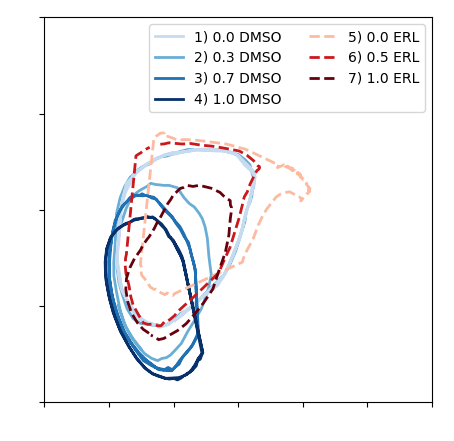

In [22]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1

lw = 2


plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='2) 0.3 DMSO')
plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[1], label='1) 0.0 DMSO')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='3) 0.7 DMSO')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='4) 1.0 DMSO')

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[1], label='5) 0.0 ERL')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) 0.5 ERL')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[4], label='7) 1.0 ERL')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [1,0,2,3,4,5,6]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)
# plt.legend(loc="upper right", ncol=2)


plt.savefig(str(SAVE_DIR)+"\\ODEs.svg", format="svg")


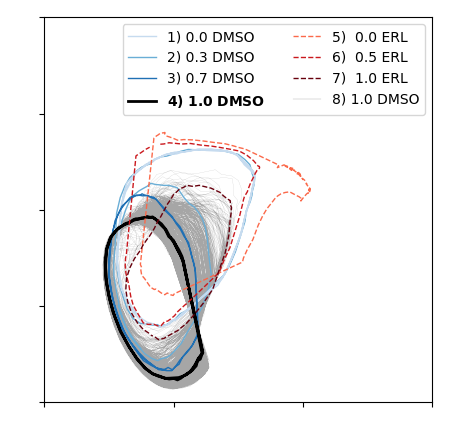

In [38]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=4
n1=5

plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
         lw=0.1, alpha=0.7, c='gray', label='8) 1.0 DMSO')

# plt.plot(embedding_all_prot_cycdi[n*trk_len:n1*trk_len,0], embedding_all_prot_cycdi[n*trk_len:n1*trk_len,1], 
#          lw=0.1, alpha=0.7, c='gray', label='8) 1.0 ERL +CycDi')

# plt.plot(embedding_all_prot_ode_conds[n*trk_len_ode:n*trk_len_ode+140,0], 
#          embedding_all_prot_ode_conds[n*trk_len_ode:n*trk_len_ode+140,1], 
#          ls='-', lw=2, alpha=1, color='black', label='1.0 ERL')

lw=1
plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='2) 0.3 DMSO')
plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[1], label='1) 0.0 DMSO')
# plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,0], 
#          embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,1], 
#          ls='-', lw=2, alpha=1, color='black', label="$\\bf{1)\ 0.0\ DMSO}$")
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='3) 0.7 DMSO')
# plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,0], 
#          embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,1], 
#          ls='-', lw=lw, alpha=1, color=colors_blue[4], label='4) 1.0 DMSO')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,1],  
         ls='-', lw=2, alpha=1, color='black', label="$\\bf{4)\ 1.0\ DMSO}$")

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+145,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+145,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[2], label='5)  0.0 ERL')
# plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+145,0], 
#          embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+145,1], 
#          ls='-', lw=2, alpha=1, color='black', label="$\\bf{5)\ 0.0\ ERL}$")
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,0], 
#          embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,1], 
#          ls='-', lw=2, alpha=1, color='black', label="$\\bf{6)\ 0.5\ ERL}$")
plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6)  0.5 ERL')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[4], label='7)  1.0 ERL')
# plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
#          embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
#          ls='-', lw=2, alpha=1, color='black', label="$\\bf{7)\ 1.0\ ERL}$")

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [2,1,3,4,5,6,7,0]
leg = plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)
for lh in leg.legendHandles: 
    lh.set_alpha(1)

leg.legendHandles[7].set_color('black')

plt.savefig(str(SAVE_DIR)+"\\DMSO_100_stoch_traj.svg", format="svg")


In [31]:
trk_len = int(len(all_prot_tmp)/len(filenames_sp))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

dmso_000_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_000_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_000_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_030_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_030_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_030_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_050_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_070_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_070_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_070_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_099_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_099_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_099_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_000_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_099_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_099_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])


In [32]:
from scipy.signal import find_peaks

In [34]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 30/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 30/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [35]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [36]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [39]:
size = (4,4)
xmin = -10
xmax = 20
ymin = 0
ymax = 20
wid = 1
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
import scipy as sp

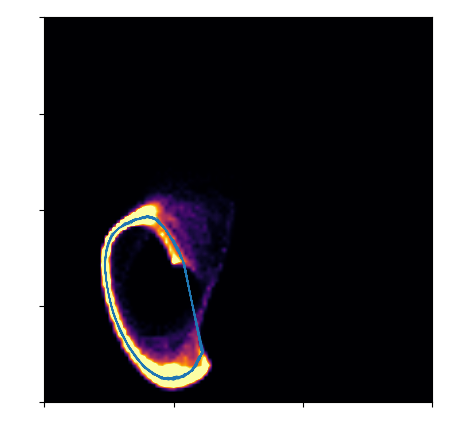

In [55]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_dmso_099[0])
y = np.array(umap_win_dmso_099[1])
H, xedges, yedges = np.histogram2d(x, y, bins=100, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0



ax = fig.gca()

tmp = embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,:]
im = plt.imshow((np.rot90(H)), extent=[xmin, xmax, ymin, ymax], 
                interpolation='bilinear', cmap='inferno', aspect='auto')
im.set_clim(0, 0.03)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=0.5, alpha=1)

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))


plt.xticks(color='w')
plt.yticks(color='w')

# cbar_ax = fig.add_axes([0.74, 0.63, 0.05, 0.2])
# cb = fig.colorbar(im, cax=cbar_ax)
# cb.ax.tick_params(labelsize=9)
# cb.ax.yaxis.set_tick_params(color='white')
# plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

plt.savefig(str(SAVE_DIR)+"\\DMSO_100_heatmap.svg", format="svg")


In [41]:
sys.path.insert(0, "./../../../Vector_Similarity/python/TS_SS")
from Vector_Similarity import *

2.23606797749979
0.9999999999999998
0.0004639582566999478


In [43]:
w_len = int(len(all_prot_tmp)/len(filenames_sp))


In [69]:
n=2
n1=3

# prot_vec=all_prot_tmp_conds[n*w_len:n1*w_len,:]
prot_vec=all_prot_tmp[n*w_len:n1*w_len,:]
offset=1
v_len=1

In [70]:
prot_inds = np.arange(n*w_len,n1*w_len,offset)

In [71]:
def calc_sim(prot_vec, offset, v_len, prot_inds):
    #prot_inds = np.arange(0,len(prot_vec),offset)
    euc_vals = []
    cos_vals = []
    TS_SS_vals = []
    
    for val in range(len(prot_inds)-2):
        vec1=all_prot_tmp[prot_inds[val]+v_len,:] - all_prot_tmp[prot_inds[val],:]
        vec2=all_prot_tmp[prot_inds[val+1]+v_len,:] - all_prot_tmp[prot_inds[val+1],:]
        euc_vals.append(Euclidean(vec1,vec2))
        cos_vals.append(Cosine(vec1,vec2))
        TS_SS_vals.append(TS_SS(vec1,vec2))
        
    return euc_vals, cos_vals, TS_SS_vals

In [72]:
euc_vals, cos_vals, TS_SS_vals = calc_sim(prot_vec, offset, v_len, prot_inds)

In [73]:
log_euc_vals=[math.log(val) for val in euc_vals]
log_TS_SS_vals=[math.log(val) for val in TS_SS_vals]

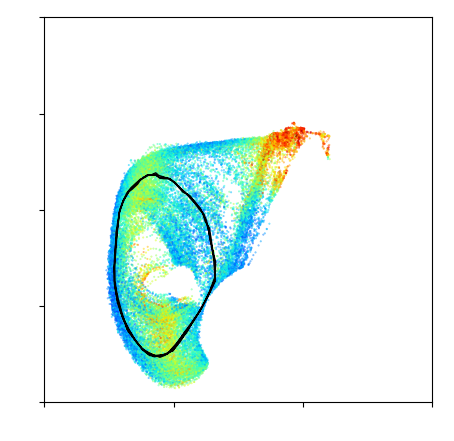

In [74]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

scatter1 = plt.scatter(embedding_all_prot[prot_inds[:-2],0], embedding_all_prot[prot_inds[:-2],1],
           s=0.2, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')

tmp = embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,:]
plt.plot(tmp[500:650,0], tmp[500:650,1],
         lw=1, alpha=1, color='black')

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

# cbar_ax = fig.add_axes([0.78, 0.65, 0.03, 0.2])
# cb = fig.colorbar(scatter1, cax=cbar_ax)
# cb.ax.tick_params(labelsize=9)

# cb.ax.yaxis.set_tick_params(color='black')
# plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='black')

plt.savefig(str(SAVE_DIR)+"\\DMSO_050_veccos.svg", format="svg")


In [89]:
colors_blue = plt.cm.Blues(np.linspace(0,1,5))
colors_red = plt.cm.Reds(np.linspace(0,1,5))
colors_accent = plt.cm.jet(np.linspace(0,1,5))

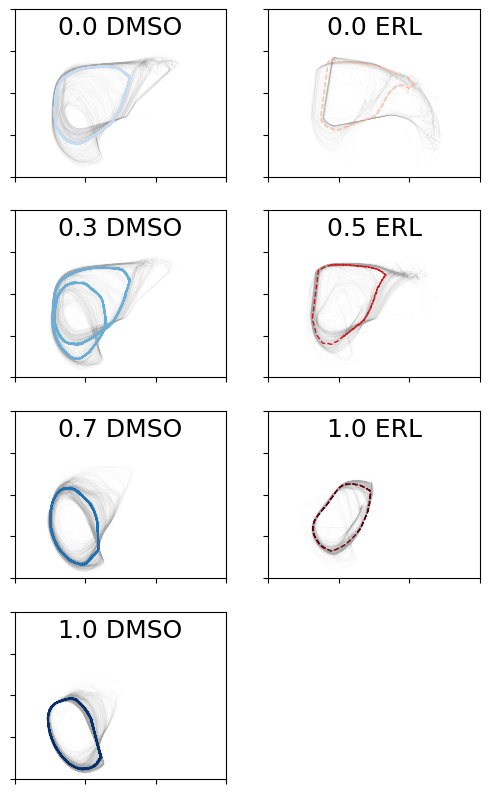

In [108]:
fig = plt.figure(figsize=(6,10))
vals = [0, 5, 1, 6, 3, 7, 4]
color_ind = [1, 1, 2, 3, 3, 4, 4]
titles = ['0.0 DMSO', '0.0 ERL', '0.3 DMSO', '0.5 ERL', '0.7 DMSO', '1.0 ERL', '1.0 DMSO']
fign = 1

for n in vals:
    plt.subplot(4,2,fign)
    n1 = n + 1
    trk_len = int(len(embedding_all_prot)/len(filenames_sp))
    trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    if (fign % 2) == 0:
        plt.plot(embedding_all_prot_ode[n*trk_len_ode:n*trk_len_ode+100,0], embedding_all_prot_ode[n*trk_len_ode:n*trk_len_ode+100,1], 
                 ls='--', lw=1, alpha=1, color=colors_red[color_ind[fign-1]])
    else:
        plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], 
                 lw=1, alpha=1, color=colors_blue[color_ind[fign-1]])


    
    plt.xlim(-10,20)
    plt.ylim(0, 20)
    plt.rcParams['axes.titley'] = 1.0
    plt.rcParams['axes.titlepad'] = -18
    plt.title(titles[fign-1])

    ax = plt.gca()
    ax.yaxis.set_tick_params(labelleft=False)
    ax.xaxis.set_tick_params(labelleft=False)

    fign += 1
    